# CSU faculty compensation summary

Aggregate compensation from the full joined faculty/pay dataset by system, university, and department.

In [159]:
from pathlib import Path

import duckdb

parquet_candidates = [
    Path("Validation/Faculty Data/csu_joined_pay.parquet"),
    Path("Faculty Data/csu_joined_pay.parquet"),
]
PARQUET_PATH = next(path for path in parquet_candidates if path.exists())

conn = duckdb.connect()
conn.from_parquet(str(PARQUET_PATH)).create_view("joined_faculty")


┌─────────────────────┬───────────────────────────────────────┬──────────────────────────┬───────────┬──────────┬──────────┬────────────┬────────────┬────────────┬────────────┬────────┬───────────┬───────────────┬──────────────────┬────────┬────────────────────┬─────────────────────────────┬────────┬─────────────────────┬─────────────────────────────────────────────┬────────────────────┬──────────────┬─────────┬────────────┬────────────┐
│        name         │                  job                  │ department_transparentCA │   base    │ overtime │  other   │ benefitsee │ benefitser │ benefitsdc │ benefitshw │  ual   │ totalpay  │ totalbenefits │ totalpaybenefits │ notes  │ year_transparentCA │           agency            │ status │        title        │             department_scraped              │       school       │ year_scraped │  major  │ source_url │ start_date │
│       varchar       │                varchar                │          double          │  double   │  double  │  d

In [160]:
faculty_summary = conn.sql("""
    SELECT
        'CSU' AS system,
        school AS university,
        department_scraped AS department,
        COUNT(totalpay) AS count,
        ROUND(AVG(totalpay), 2) AS mean,
        ROUND(MEDIAN(totalpay), 2) AS median,
        ROUND(STDDEV_SAMP(totalpay), 2) AS std,
        ROUND(
            QUANTILE_CONT(totalpay, 0.75) - QUANTILE_CONT(totalpay, 0.25),
            2
        ) AS iqr
    FROM joined_faculty
    WHERE school IS NOT NULL
      AND department_scraped IS NOT NULL
      AND totalpay IS NOT NULL
    GROUP BY system, university, department
    ORDER BY system, university, department
""")

faculty_summary


┌─────────┬─────────────────────────┬────────────────────────────────────────────────────────┬───────┬───────────┬───────────┬──────────┬───────────┐
│ system  │       university        │                       department                       │ count │   mean    │  median   │   std    │    iqr    │
│ varchar │         varchar         │                        varchar                         │ int64 │  double   │  double   │  double  │  double   │
├─────────┼─────────────────────────┼────────────────────────────────────────────────────────┼───────┼───────────┼───────────┼──────────┼───────────┤
│ CSU     │ CSU Bakersfield         │ Accounting and Finances                                │    15 │  77516.72 │       0.0 │ 87679.72 │ 158355.51 │
│ CSU     │ CSU Bakersfield         │ Advanced Educational Studies                           │    14 │  47157.85 │       0.0 │ 58322.78 │  96488.91 │
│ CSU     │ CSU Bakersfield         │ Anthropology                                           │     1

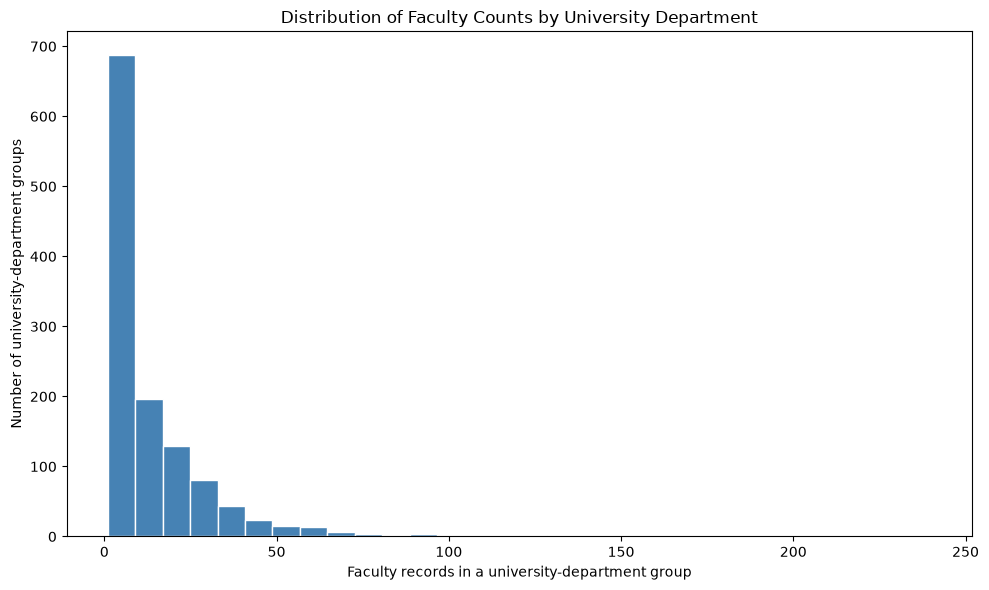

In [161]:
import matplotlib.pyplot as plt

# Each value is the number of faculty records in one university-department group.
counts = [row[0] for row in faculty_summary.project("count").fetchall()]
bins = min(30, max(1, len(set(counts))))

plt.figure(figsize=(10, 6))
plt.hist(counts, bins=bins, color="steelblue", edgecolor="white")
plt.title("Distribution of Faculty Counts by University Department")
plt.xlabel("Faculty records in a university-department group")
plt.ylabel("Number of university-department groups")
plt.tight_layout()
plt.show()


In [162]:
# Show every group tied for the highest or lowest faculty-record count.
faculty_summary.create_view("faculty_summary_view")

count_extremes = conn.sql("""
    SELECT 'Highest count' AS result, *
    FROM faculty_summary_view
    WHERE count = (SELECT MAX(count) FROM faculty_summary_view)

    UNION ALL

    SELECT 'Lowest count' AS result, *
    FROM faculty_summary_view
    WHERE count = (SELECT MIN(count) FROM faculty_summary_view)
    ORDER BY count DESC, university, department
""")

count_extremes


┌───────────────┬─────────┬────────────────────────────────┬────────────────────────────────────────────────────┬───────┬───────────┬───────────┬──────────┬──────────┐
│    result     │ system  │           university           │                     department                     │ count │   mean    │  median   │   std    │   iqr    │
│    varchar    │ varchar │            varchar             │                      varchar                       │ int64 │  double   │  double   │  double  │  double  │
├───────────────┼─────────┼────────────────────────────────┼────────────────────────────────────────────────────┼───────┼───────────┼───────────┼──────────┼──────────┤
│ Highest count │ CSU     │ CSU Long Beach                 │ Index.Php                                          │   240 │  55508.09 │  17542.03 │ 72560.72 │ 91397.28 │
│ Lowest count  │ CSU     │ CSU Bakersfield                │ Anthropology                                       │     1 │ 108283.45 │ 108283.45 │     NULL │    

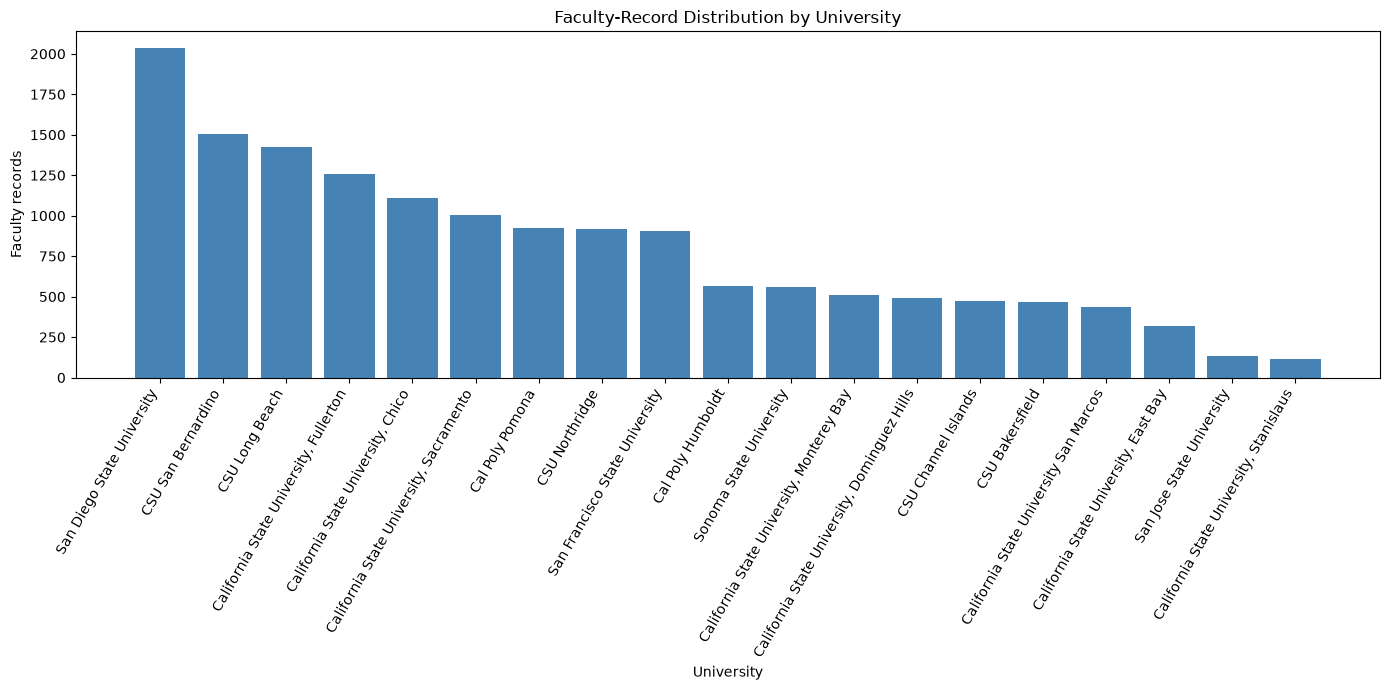

In [163]:
import matplotlib.pyplot as plt

# Total faculty-record counts for each university.
university_counts = conn.sql("""
    SELECT
        university,
        SUM(count) AS faculty_count
    FROM faculty_summary_view
    GROUP BY university
    ORDER BY faculty_count DESC
""")

university_rows = university_counts.fetchall()
universities = [row[0] for row in university_rows]
faculty_counts = [row[1] for row in university_rows]

plt.figure(figsize=(14, 7))
plt.bar(universities, faculty_counts, color="steelblue")
plt.title("Faculty-Record Distribution by University")
plt.xlabel("University")
plt.ylabel("Faculty records")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


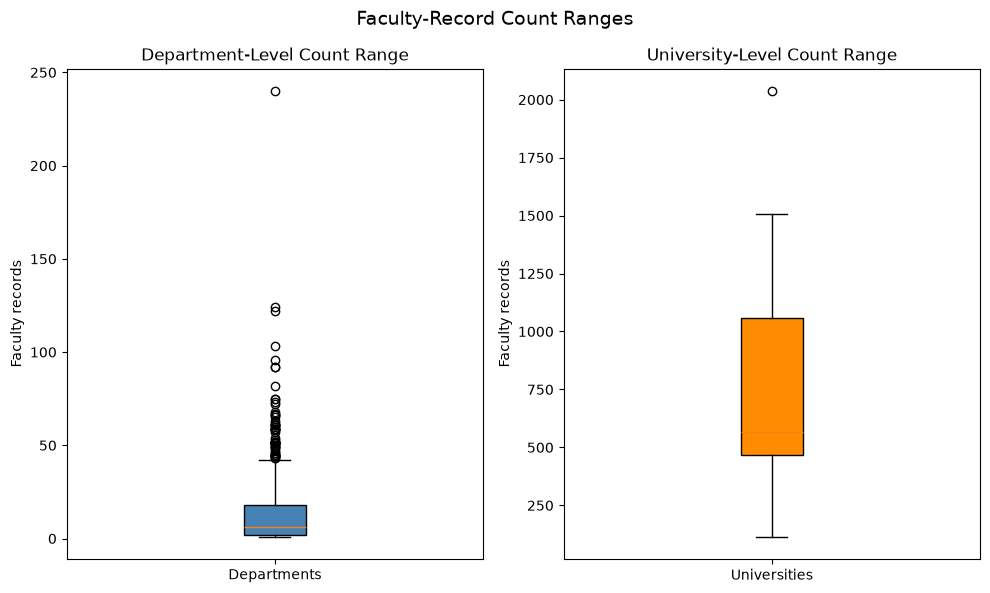

In [164]:
import matplotlib.pyplot as plt

# Compare the count ranges at the department and university levels.
department_count_values = [row[0] for row in faculty_summary.project("count").fetchall()]
university_count_values = [row[1] for row in university_counts.fetchall()]

fig, axes = plt.subplots(1, 2, figsize=(10, 6))

axes[0].boxplot(department_count_values, tick_labels=["Departments"], patch_artist=True,
                boxprops={"facecolor": "steelblue"})
axes[0].set_title("Department-Level Count Range")
axes[0].set_ylabel("Faculty records")

axes[1].boxplot(university_count_values, tick_labels=["Universities"], patch_artist=True,
                boxprops={"facecolor": "darkorange"})
axes[1].set_title("University-Level Count Range")
axes[1].set_ylabel("Faculty records")

fig.suptitle("Faculty-Record Count Ranges", fontsize=14)
plt.tight_layout()
plt.show()


In [165]:
# Missing values include NULLs and blank text values in the full joined dataset.
columns = [row[0] for row in conn.sql("DESCRIBE joined_faculty").fetchall()]
missing_queries = []

for column in columns:
    quoted_column = column.replace('\"', '\"\"')
    quoted_name = column.replace("'", "''")
    missing_queries.append(f"""
        SELECT
            '{quoted_name}' AS column_name,
            SUM(CASE
                WHEN \"{quoted_column}\" IS NULL
                  OR CAST(\"{quoted_column}\" AS VARCHAR) = ''
                THEN 1 ELSE 0
            END)::BIGINT AS missing_count,
            COUNT(*) AS total_rows,
            ROUND(100.0 * missing_count / total_rows, 2) AS missing_percent
        FROM joined_faculty
    """)

missing_data_stats = conn.sql(" UNION ALL ".join(missing_queries) +
                             " ORDER BY missing_percent DESC, column_name")
missing_data_stats


┌──────────────────────────┬───────────────┬────────────┬─────────────────┐
│       column_name        │ missing_count │ total_rows │ missing_percent │
│         varchar          │     int64     │   int64    │     double      │
├──────────────────────────┼───────────────┼────────────┼─────────────────┤
│ benefitsdc               │         15501 │      15501 │           100.0 │
│ benefitsee               │         15501 │      15501 │           100.0 │
│ benefitser               │         15501 │      15501 │           100.0 │
│ benefitshw               │         15501 │      15501 │           100.0 │
│ department_transparentCA │         15501 │      15501 │           100.0 │
│ notes                    │         15501 │      15501 │           100.0 │
│ status                   │         15501 │      15501 │           100.0 │
│ ual                      │         15501 │      15501 │           100.0 │
│ source_url               │         14078 │      15501 │           90.82 │
│ major     

# UC faculty compensation summary

The following cells repeat the university-department analysis for the UC faculty dataset.

In [166]:
from pathlib import Path

uc_parquet_candidates = [
    Path("Validation/Faculty Data/uc-faculty.parquet"),
    Path("Faculty Data/uc-faculty.parquet"),
]
UC_PARQUET_PATH = next(path for path in uc_parquet_candidates if path.exists())

conn.from_parquet(str(UC_PARQUET_PATH)).create_view("uc_faculty")


┌───────┬──────────┬────────────┬────────────┬────────────────────────┬────────────────────────────────┬───────────┬──────────┬──────────────┬───────────┐
│ year  │  campus  │ last_name  │ first_name │       title_name       │           department           │ gross_pay │ base_pay │ overtime_pay │ other_pay │
│ int16 │ varchar  │  varchar   │  varchar   │        varchar         │            varchar             │   int32   │  int32   │    int32     │   int32   │
├───────┼──────────┼────────────┼────────────┼────────────────────────┼────────────────────────────────┼───────────┼──────────┼──────────────┼───────────┤
│  2024 │ asucla   │ abbassi    │ pouria     │ dir exec               │ executive director             │    390489 │   356085 │            0 │     34405 │
│  2024 │ asucla   │ mehdian    │ kamran     │ dir                    │ systems development            │    247343 │   236450 │            0 │     10893 │
│  2024 │ asucla   │ baker      │ donna      │ dir                    

In [167]:
uc_faculty_summary = conn.sql("""
    SELECT
        'UC' AS system,
        campus AS university,
        department,
        COUNT(gross_pay) AS count,
        ROUND(AVG(gross_pay), 2) AS mean,
        ROUND(MEDIAN(gross_pay), 2) AS median,
        ROUND(STDDEV_SAMP(gross_pay), 2) AS std,
        ROUND(
            QUANTILE_CONT(gross_pay, 0.75) - QUANTILE_CONT(gross_pay, 0.25),
            2
        ) AS iqr
    FROM uc_faculty
    WHERE campus IS NOT NULL
      AND department IS NOT NULL
      AND gross_pay IS NOT NULL
    GROUP BY system, university, department
    ORDER BY system, university, department
""")

uc_faculty_summary


┌─────────┬────────────┬────────────────────────────────┬───────┬───────────┬──────────┬──────────┬──────────┐
│ system  │ university │           department           │ count │   mean    │  median  │   std    │   iqr    │
│ varchar │  varchar   │            varchar             │ int64 │  double   │  double  │  double  │  double  │
├─────────┼────────────┼────────────────────────────────┼───────┼───────────┼──────────┼──────────┼──────────┤
│ UC      │ asucla     │                                │   207 │   1140.93 │    584.0 │  1638.81 │    887.0 │
│ UC      │ asucla     │ 221 luvalle food               │     1 │     488.0 │    488.0 │     NULL │      0.0 │
│ UC      │ asucla     │ academic support div office    │     8 │  89154.75 │  90885.0 │ 17015.14 │ 20745.25 │
│ UC      │ asucla     │ academic support div office    │     6 │   84470.5 │  83917.0 │  9807.39 │  16827.5 │
│ UC      │ asucla     │ accounts payable               │    33 │  34224.64 │   5573.0 │ 34985.32 │  55379.0 │
│

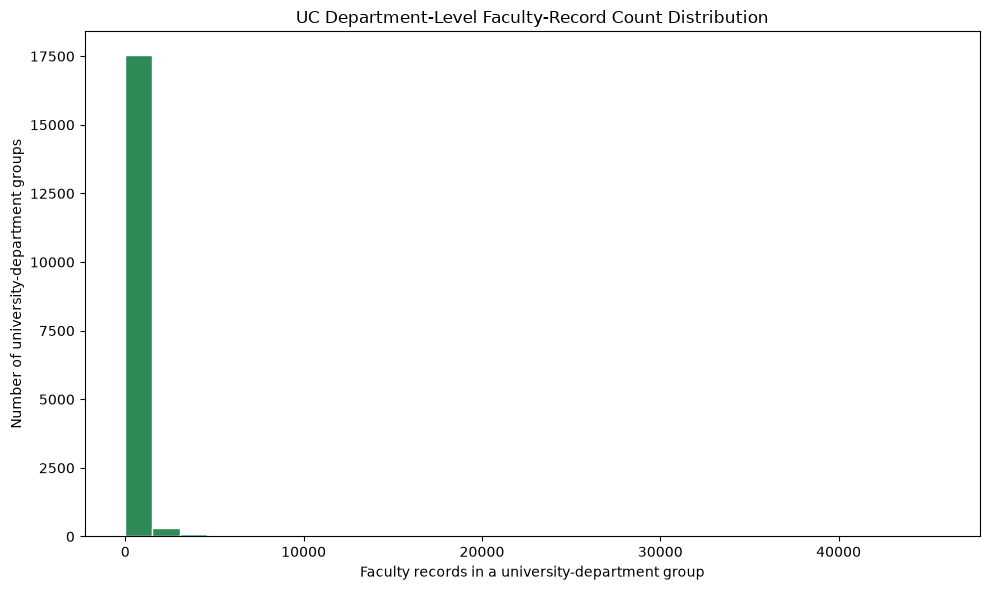

In [168]:
import matplotlib.pyplot as plt

uc_department_counts = [row[0] for row in uc_faculty_summary.project("count").fetchall()]
uc_bins = min(30, max(1, len(set(uc_department_counts))))

plt.figure(figsize=(10, 6))
plt.hist(uc_department_counts, bins=uc_bins, color="seagreen", edgecolor="white")
plt.title("UC Department-Level Faculty-Record Count Distribution")
plt.xlabel("Faculty records in a university-department group")
plt.ylabel("Number of university-department groups")
plt.tight_layout()
plt.show()


In [169]:
# Include ties for the UC highest and lowest counts.
uc_faculty_summary.create_view("uc_faculty_summary_view")

uc_count_extremes = conn.sql("""
    SELECT 'Highest count' AS result, *
    FROM uc_faculty_summary_view
    WHERE count = (SELECT MAX(count) FROM uc_faculty_summary_view)
    UNION ALL
    SELECT 'Lowest count' AS result, *
    FROM uc_faculty_summary_view
    WHERE count = (SELECT MIN(count) FROM uc_faculty_summary_view)
    ORDER BY count DESC, university, department
""")

uc_count_extremes


┌───────────────┬─────────┬────────────┬────────────────────────────────┬───────┬──────────┬──────────┬─────────┬─────────┐
│    result     │ system  │ university │           department           │ count │   mean   │  median  │   std   │   iqr   │
│    varchar    │ varchar │  varchar   │            varchar             │ int64 │  double  │  double  │ double  │ double  │
├───────────────┼─────────┼────────────┼────────────────────────────────┼───────┼──────────┼──────────┼─────────┼─────────┤
│ Highest count │ UC      │ davis      │ ucdmc medical center           │ 45646 │ 77276.83 │  62344.0 │ 47416.6 │ 72110.0 │
│ Lowest count  │ UC      │ asucla     │ 221 luvalle food               │     1 │    488.0 │    488.0 │    NULL │     0.0 │
│ Lowest count  │ UC      │ asucla     │ bright success center          │     1 │   2235.0 │   2235.0 │    NULL │     0.0 │
│ Lowest count  │ UC      │ asucla     │ campus photo studio            │     1 │   4070.0 │   4070.0 │    NULL │     0.0 │
│ Lowest

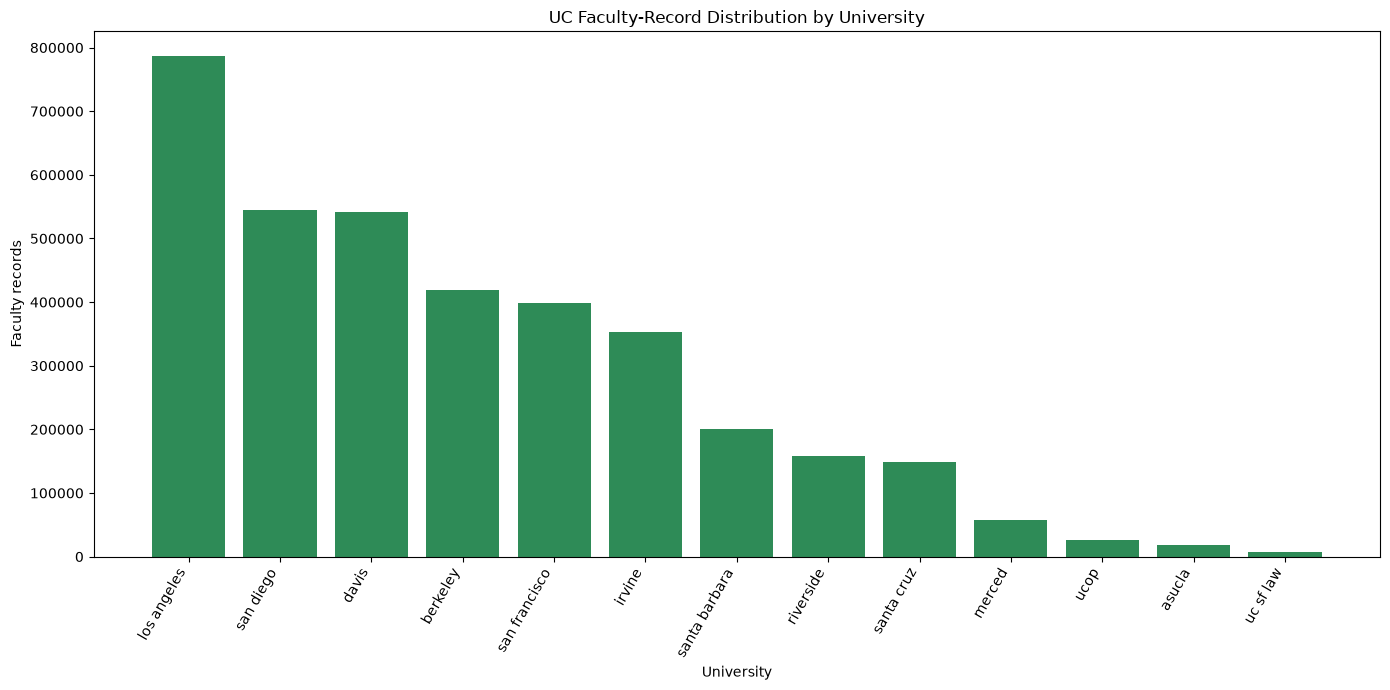

In [170]:
import matplotlib.pyplot as plt

uc_university_counts = conn.sql("""
    SELECT university, SUM(count) AS faculty_count
    FROM uc_faculty_summary_view
    GROUP BY university
    ORDER BY faculty_count DESC
""")

uc_university_rows = uc_university_counts.fetchall()
uc_universities = [row[0] for row in uc_university_rows]
uc_faculty_counts = [row[1] for row in uc_university_rows]

plt.figure(figsize=(14, 7))
plt.bar(uc_universities, uc_faculty_counts, color="seagreen")
plt.title("UC Faculty-Record Distribution by University")
plt.xlabel("University")
plt.ylabel("Faculty records")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


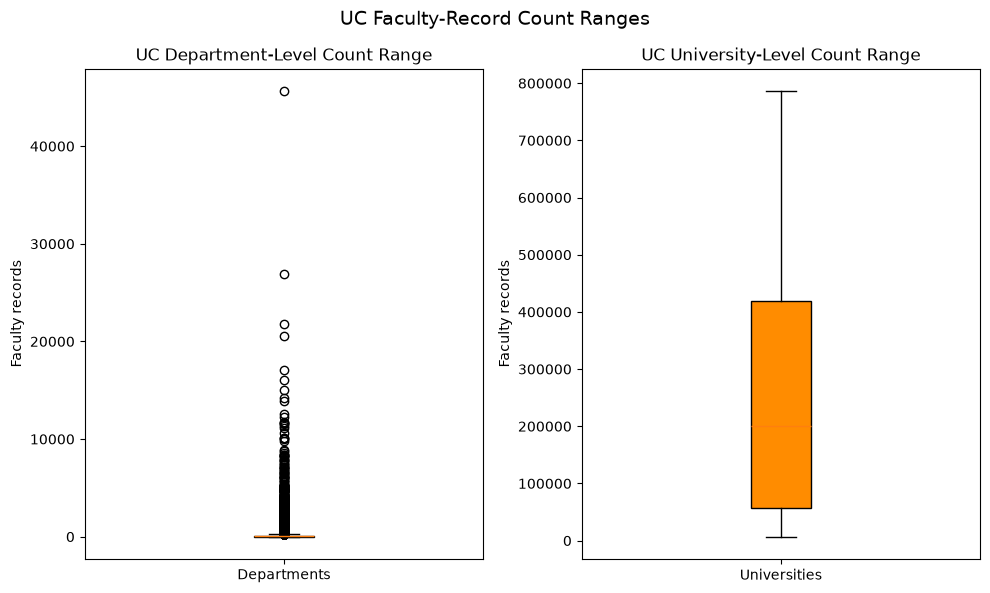

In [171]:
import matplotlib.pyplot as plt

uc_university_count_values = [row[1] for row in uc_university_counts.fetchall()]

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].boxplot(uc_department_counts, tick_labels=["Departments"], patch_artist=True,
                boxprops={"facecolor": "seagreen"})
axes[0].set_title("UC Department-Level Count Range")
axes[0].set_ylabel("Faculty records")

axes[1].boxplot(uc_university_count_values, tick_labels=["Universities"], patch_artist=True,
                boxprops={"facecolor": "darkorange"})
axes[1].set_title("UC University-Level Count Range")
axes[1].set_ylabel("Faculty records")

fig.suptitle("UC Faculty-Record Count Ranges", fontsize=14)
plt.tight_layout()
plt.show()


In [172]:
# Missing values include NULLs and blank text values in the full UC dataset.
uc_columns = [row[0] for row in conn.sql("DESCRIBE uc_faculty").fetchall()]
uc_missing_queries = []

for column in uc_columns:
    quoted_column = column.replace('\"', '\"\"')
    quoted_name = column.replace("'", "''")
    uc_missing_queries.append(f"""
        SELECT
            '{quoted_name}' AS column_name,
            SUM(CASE
                WHEN \"{quoted_column}\" IS NULL
                  OR CAST(\"{quoted_column}\" AS VARCHAR) = ''
                THEN 1 ELSE 0
            END)::BIGINT AS missing_count,
            COUNT(*) AS total_rows,
            ROUND(100.0 * missing_count / total_rows, 2) AS missing_percent
        FROM uc_faculty
    """)

uc_missing_data_stats = conn.sql(" UNION ALL ".join(uc_missing_queries) +
                                " ORDER BY missing_percent DESC, column_name")
uc_missing_data_stats


┌──────────────┬───────────────┬────────────┬─────────────────┐
│ column_name  │ missing_count │ total_rows │ missing_percent │
│   varchar    │     int64     │   int64    │     double      │
├──────────────┼───────────────┼────────────┼─────────────────┤
│ department   │           341 │    3660661 │            0.01 │
│ base_pay     │             0 │    3660661 │             0.0 │
│ campus       │             0 │    3660661 │             0.0 │
│ first_name   │             1 │    3660661 │             0.0 │
│ gross_pay    │             0 │    3660661 │             0.0 │
│ last_name    │             0 │    3660661 │             0.0 │
│ other_pay    │             0 │    3660661 │             0.0 │
│ overtime_pay │             0 │    3660661 │             0.0 │
│ title_name   │             4 │    3660661 │             0.0 │
│ year         │             0 │    3660661 │             0.0 │
└──────────────┴───────────────┴────────────┴─────────────────┘
  10 rows                               

# CSU department buckets

Apply the existing department-bucketing rules, in their original order, to the joined CSU data.

In [179]:
# Make the joined CSU department field available under the rule's expected name.
conn.execute("""
    CREATE OR REPLACE TABLE faculty_salaries AS
    SELECT *, department_scraped AS department
    FROM joined_faculty
""")

bucket_sql = """
SELECT *,
CASE
    WHEN 
        department ILIKE '%computer%' 
        OR department ILIKE '%comp sci%'
        OR department ILIKE '%cmptr sci%'
        OR department ILIKE '%computing%'
        OR department ILIKE '%software%'
        OR department ILIKE '%informatics%'
        OR department ILIKE '%cyber%'
        OR department ILIKE '%data science%'
        OR department ILIKE '%information studies%'
        OR department ILIKE '%school of info%'
    THEN 'Computer Science'
    
    WHEN 
        department ILIKE '%medicine%'
        OR department ILIKE '%surgery%'
        OR department ILIKE '%vm:%'
        OR department ILIKE '%med:%'
        OR department ILIKE '%!_%' ESCAPE '!' -- For some reason all of the _'s for UC's are medicine or health lol
        OR department ILIKE '%nurs%'
        OR department ILIKE '%dentistry%'
        OR department ILIKE '%pharma%'
        OR department ILIKE '%gynecology%'
        OR department ILIKE '%urology%'
        OR department ILIKE '%oncology%'
        OR department ILIKE '%family med%'
        OR department ILIKE '%radiation%'
        OR department ILIKE '%ophthalmology%'
        OR department ILIKE '%pathology%'
        OR department ILIKE '%peds%'
        OR department ILIKE '%dermatology%'
        OR department ILIKE '%pediatrics%'
        OR department ILIKE '%anesthesiology%'
        OR department ILIKE '%optometry%'
        OR department ILIKE '%psychiatry%'
        OR department ILIKE '%emerg med%'
        OR department ILIKE '%radiolog%'
        OR department ILIKE '%radiation%'
        OR department ILIKE '%anesthes%'
        OR department ILIKE '%public health%'
        OR department ILIKE '%med ed administration%'
        OR department ILIKE '%deans office-school of medicin%'
        OR department ILIKE '%semel institute%'
        OR department ILIKE '%school of med%'
        OR department ILIKE '%dom cardiology%'
        OR department ILIKE '%ophth clinical%'
        OR department ILIKE '%med-campus%'
        OR department ILIKE '%dntl sci%'
        OR department ILIKE '%ob/gyn%'
        OR department ILIKE '%ambulatory%'
        OR department ILIKE '%electronic health record%'
        OR department ILIKE '%electrocardiology%'
        OR department ILIKE '%epidemiology%'
        OR department ILIKE '%otolaryngology%'
        OR department ILIKE '%hematology%'
        OR department ILIKE '%school of public health%'
        OR department ILIKE '%health policy and management%'
        OR department ILIKE '%health sciences%'
        OR department ILIKE '%lppi: instr & research%'
        OR department ILIKE 'dom %'
        OR department ILIKE 'som %'
        OR department ILIKE 'som-%'
        OR department ILIKE '%obgyn%'
        OR department ILIKE '%sfgh%'
        OR department ILIKE 'psych-%'
        OR department ILIKE 'fcm-%'
    THEN 'Medicine & Health Sciences'
    
    WHEN 
        department ILIKE '%business%'
        OR department ILIKE '%econ%'
        OR department ILIKE '%finance%'
        OR department ILIKE '%of managemen%'
        OR department ILIKE '%haas core%'
        OR department ILIKE '%technology management program%'
        OR department ILIKE '%grad.sch. int.relat./pac.stud.%'
    THEN 'Business, Economics & Finance'
    
    WHEN
        department ILIKE '%engineer%'
        OR department ILIKE '%engr%'
        OR department ILIKE '%mech%'
        OR department ILIKE '%civil%'
        OR department ILIKE '%areo%'
        OR department ILIKE '%electric%'
        OR department ILIKE '%soe-ams%'
        OR department ILIKE '%chemical%'
        OR department ILIKE '%industrial%'
        OR department ILIKE '%material%'
        OR department ILIKE '%soece-ee-tm-cm%'
    THEN 'Engineering'
    
    WHEN
        department ILIKE '%math%'
        OR department ILIKE '%stat%'
        OR department ILIKE '%statistics%'
        OR department ILIKE '%bio%'
        OR department ILIKE '%neuro%'
        OR department ILIKE '%phys%'
        OR department ILIKE '%land air & water resources%'
        OR department ILIKE '%climate/atmos sci/phy oceanog%'
        OR department ILIKE '%ocean sciences%'
        OR department ILIKE '%entomology%'
        OR department ILIKE '%physics%'
        OR department ILIKE '%astro%'
        OR department ILIKE '%chem%'
        OR department ILIKE '%sio dep%'
        OR department ILIKE '%molecular, cell%'
        OR department ILIKE '%earth%'
        OR department ILIKE '%oceanic%'
        OR department ILIKE '%ecology%'
        OR department ILIKE '%genetics%'
        OR department ILIKE '%igpp%'
        OR department ILIKE '%geosciences%'
        OR department ILIKE '%oceanography%'
        OR department ILIKE '%geology%'
        OR department ILIKE '%viticulture%'
        OR department ILIKE '%nematology%'
        OR department ILIKE '%demography%'
    THEN 'Science & Mathematics'
    
    WHEN
        department ILIKE '%plant science%'
        OR department ILIKE '%agriculture%'
        OR department ILIKE '%espm%'
        OR department ILIKE '%nutrition%'
        OR department ILIKE '%inst of environment and sustai%'
        OR department ILIKE '%energy & resources group%'
        OR department ILIKE '%animal%'
        OR department ILIKE '%food science%'
        OR department ILIKE '%food safety%'
    THEN 'Agriculture, Food & Animal'
    
    WHEN
        department ILIKE '%architec%'
        OR department ILIKE '%planning%'
        OR department ILIKE '%urban%'
        OR department ILIKE '%landscape arch%'
        OR department ILIKE '%environmental%'
    THEN 'Architecture & Environmental Design'
    
    WHEN
        department ILIKE '%language%'
        OR department ILIKE '%linguistics%'
        OR department ILIKE '%humanities%'
        OR department ILIKE '%english%'
        OR department ILIKE '%literature%'
        OR department ILIKE '%writing%'
        OR department ILIKE '%history%'
        OR department ILIKE '%philosophy%'
        OR department ILIKE '%french%'
        OR department ILIKE '%spanish%'
        OR department ILIKE '%german%'
        OR department ILIKE '%japanese%'
        OR department ILIKE '%dance%'
        OR department ILIKE '%african%'
        OR department ILIKE '%music%'
        OR department ILIKE '%division of arts%'
        OR department ILIKE '%classics%'
        OR department ILIKE '%film%'
        OR department ILIKE '%visual arts%'
        OR department ILIKE '%theatre%'
        OR department ILIKE '%religious%'
        OR department ILIKE '%theater%'
        OR department ILIKE '%asian lang%'
        OR department ILIKE '%eastern lang%'
        OR department ILIKE '%world arts%'
        OR department ILIKE '%southeast asian%'
        OR department ILIKE '%drama department%'
        OR department ILIKE '%department of chicana%'
        OR department ILIKE '%asian-american%'
        OR department ILIKE '%asian%'
        OR department ILIKE '%studio art%'
        OR department ILIKE '%art%'
        OR department ILIKE '%design program%'
        OR department ILIKE '%rhetoric%'
        OR department ILIKE '%near eastern%'
        OR department ILIKE '%chicano%'
        OR department ILIKE '%department of design%'
        OR department ILIKE '%media%'
        OR department ILIKE '%institute for society and gene%'
        OR department ILIKE '%college of creative studies%'
        OR department ILIKE '%american studies%'
        OR department ILIKE '%italian studies%'
        OR department ILIKE '%native american studies%'
        OR department ILIKE '%performance, play & design%'
        OR department ILIKE '%science & technology studies%'
        OR department ILIKE '%drama%'
        OR department ILIKE '%hispanic%'
        OR department ILIKE '%italian%'
        OR department ILIKE '%scandinavian%'
        OR department ILIKE '%slavic%'
        OR department ILIKE '%greek & roman%'
    THEN 'Humanities & Languages'
    
    WHEN
        department ILIKE '%anthropology%'
        OR department ILIKE '%social science%'
        OR department ILIKE '%sociology%'
        OR department ILIKE '%political science%'
        OR department ILIKE '%politics%'
        OR department ILIKE '%ethnic stud%'
        OR department ILIKE '%women%'
        OR department ILIKE '%psychology%'
        OR department ILIKE '%psychological%'
        OR department ILIKE '%cognitive science%'
        OR department ILIKE '%global & intl studies%'
        OR department ILIKE '%soc sci undergrad%'
        OR department ILIKE '%comm%'
        OR department ILIKE '%gender%'
        OR department ILIKE '%child%'
        OR department ILIKE '%geography%'
        OR department ILIKE '%human ecology%'
        OR department ILIKE '%social welfare%'
        OR department ILIKE '%global & international studies%'
        OR department ILIKE '%african am studies%'
        OR department ILIKE '%black studies%'
        OR department ILIKE '%studies%'
    THEN 'Social Sciences & Communication'
    
    WHEN
        department ILIKE '%education%'
        OR department ILIKE '%public policy%'
        OR department ILIKE '%policy&strategy%'
        OR department ILIKE 'jd program'
        OR department ILIKE '%law%'
        OR department ILIKE '%legal%'
        OR department ILIKE '%journalism%'
        OR department ILIKE '%teaching%'
    THEN 'Education & Public Administration'
    
    ELSE 'Other'
END AS dep_bucket 
FROM faculty_salaries
"""

conn.execute(f"""
CREATE OR REPLACE TABLE faculty_salaries AS
{bucket_sql}
""")

In [180]:
# Aggregate the bucketed CSU data by system, university, and new department bucket.
csu_bucket_summary = conn.sql("""
    SELECT
        'CSU' AS system,
        school AS university,
        dep_bucket AS department,
        COUNT(totalpay) AS count,
        ROUND(AVG(totalpay), 2) AS mean,
        ROUND(MEDIAN(totalpay), 2) AS median,
        ROUND(STDDEV_SAMP(totalpay), 2) AS std,
        ROUND(
            QUANTILE_CONT(totalpay, 0.75) - QUANTILE_CONT(totalpay, 0.25),
            2
        ) AS iqr
    FROM faculty_salaries
    WHERE school IS NOT NULL
      AND totalpay IS NOT NULL
    GROUP BY school, dep_bucket
    ORDER BY system, university, department
""")

csu_bucket_summary


┌─────────┬───────────────────────────┬─────────────────────────────────────┬───────┬──────────┬───────────┬──────────┬───────────┐
│ system  │        university         │             department              │ count │   mean   │  median   │   std    │    iqr    │
│ varchar │          varchar          │               varchar               │ int64 │  double  │  double   │  double  │  double   │
├─────────┼───────────────────────────┼─────────────────────────────────────┼───────┼──────────┼───────────┼──────────┼───────────┤
│ CSU     │ CSU Bakersfield           │ Business, Economics & Finance       │    18 │  78652.7 │  50781.03 │ 83896.33 │ 150549.13 │
│ CSU     │ CSU Bakersfield           │ Computer Science                    │    20 │ 57813.61 │  57868.92 │ 59176.91 │ 116608.98 │
│ CSU     │ CSU Bakersfield           │ Education & Public Administration   │    64 │ 34669.05 │       0.0 │ 58737.28 │  71176.62 │
│ CSU     │ CSU Bakersfield           │ Engineering                         

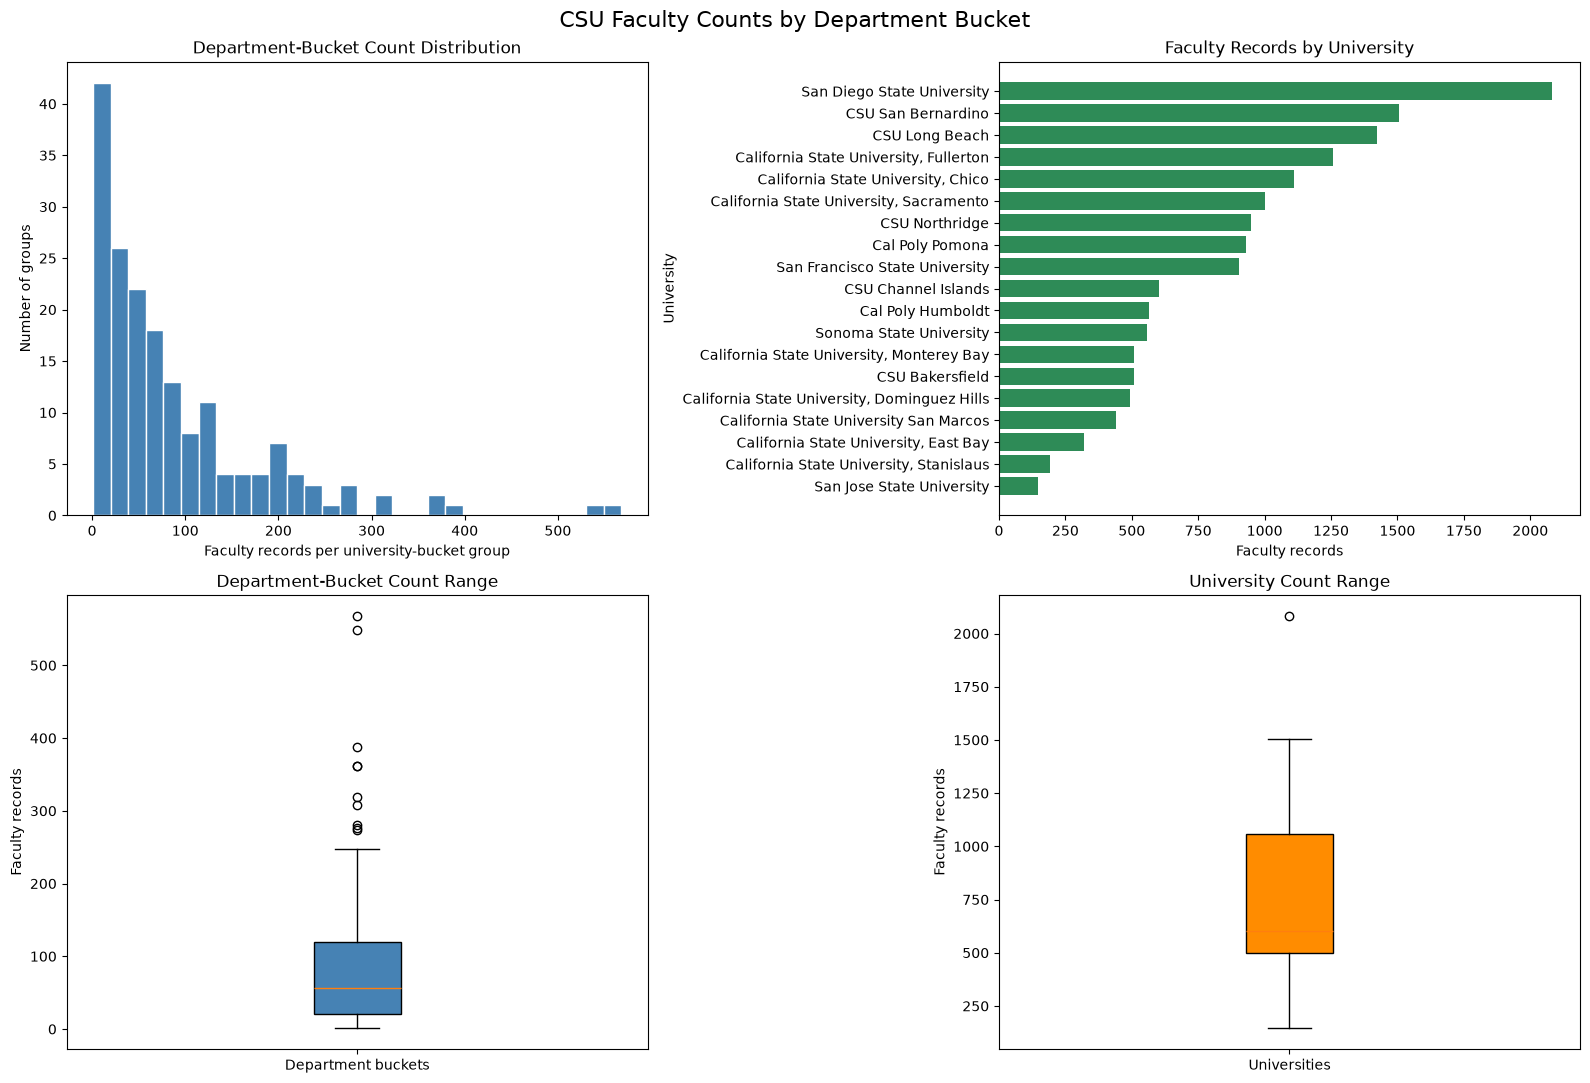

In [181]:
import matplotlib.pyplot as plt

# Department-bucket counts and total counts for each CSU university.
csu_bucket_summary.create_view("csu_bucket_summary_view")
bucket_department_counts = [row[0] for row in csu_bucket_summary.project("count").fetchall()]
bucket_university_counts = conn.sql("""
    SELECT university, SUM(count) AS faculty_count
    FROM csu_bucket_summary_view
    GROUP BY university
    ORDER BY faculty_count DESC
""").fetchall()
bucket_universities = [row[0] for row in bucket_university_counts]
bucket_university_values = [row[1] for row in bucket_university_counts]
bucket_bins = min(30, max(1, len(set(bucket_department_counts))))

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

axes[0, 0].hist(bucket_department_counts, bins=bucket_bins, color="steelblue", edgecolor="white")
axes[0, 0].set_title("Department-Bucket Count Distribution")
axes[0, 0].set_xlabel("Faculty records per university-bucket group")
axes[0, 0].set_ylabel("Number of groups")

axes[0, 1].barh(bucket_universities, bucket_university_values, color="seagreen")
axes[0, 1].set_title("Faculty Records by University")
axes[0, 1].set_xlabel("Faculty records")
axes[0, 1].set_ylabel("University")
axes[0, 1].invert_yaxis()

axes[1, 0].boxplot(bucket_department_counts, tick_labels=["Department buckets"],
                     patch_artist=True, boxprops={"facecolor": "steelblue"})
axes[1, 0].set_title("Department-Bucket Count Range")
axes[1, 0].set_ylabel("Faculty records")

axes[1, 1].boxplot(bucket_university_values, tick_labels=["Universities"],
                     patch_artist=True, boxprops={"facecolor": "darkorange"})
axes[1, 1].set_title("University Count Range")
axes[1, 1].set_ylabel("Faculty records")

fig.suptitle("CSU Faculty Counts by Department Bucket", fontsize=16)
plt.tight_layout()
plt.show()


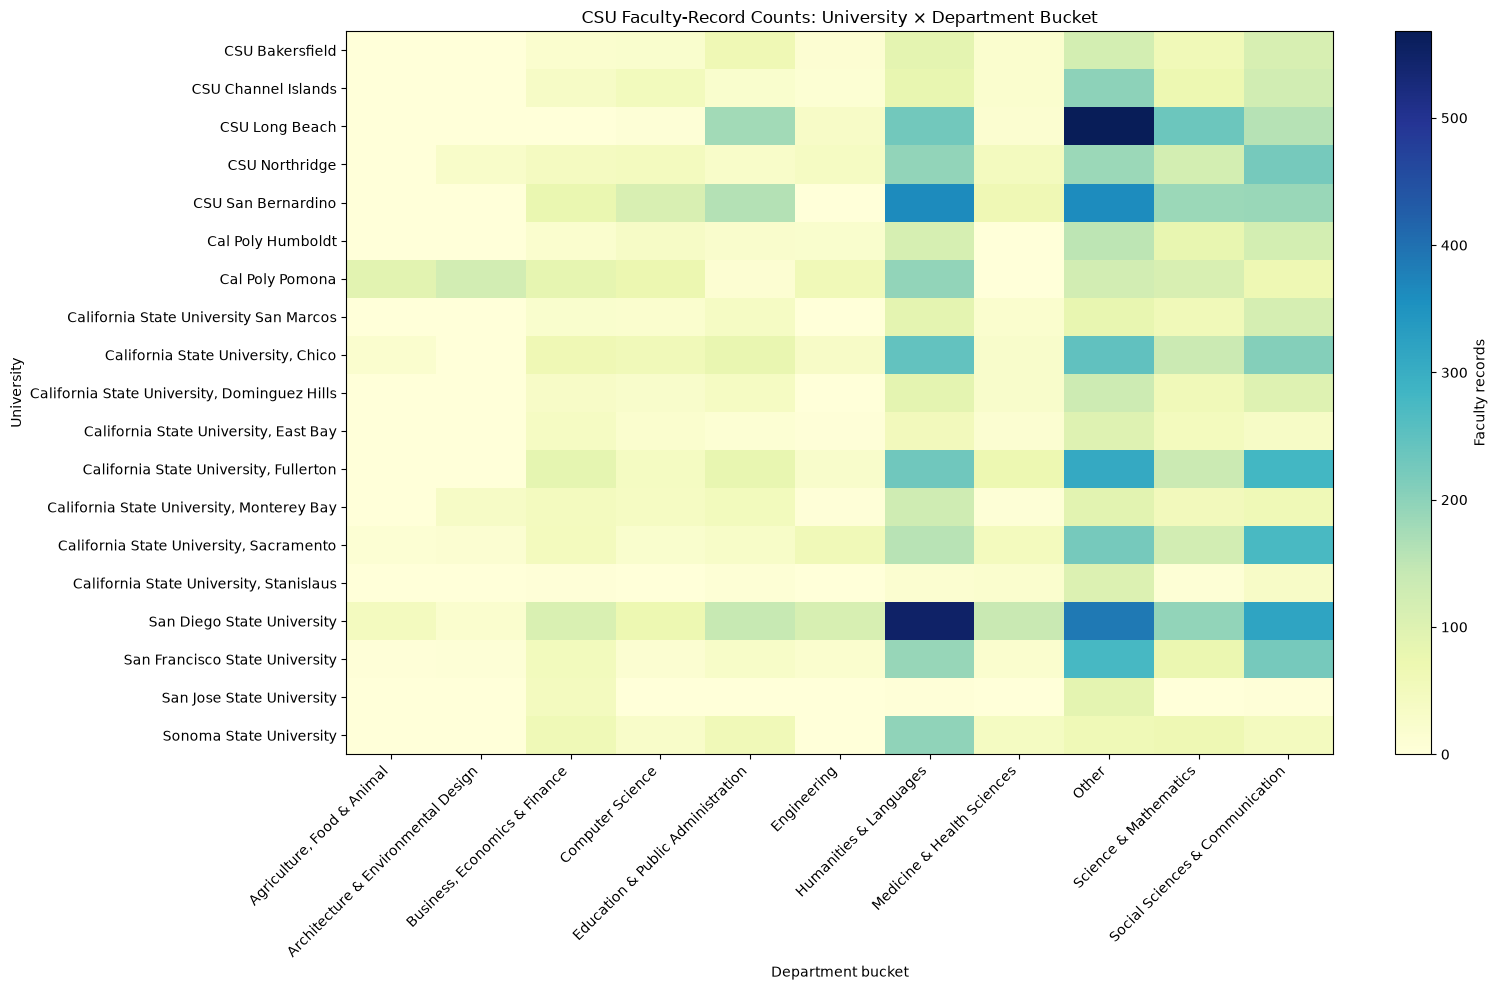

In [182]:
import matplotlib.pyplot as plt

csu_bucket_summary.create_view("csu_bucket_heatmap_view", replace=True)
heatmap_rows = conn.sql("""
    SELECT university, department, count
    FROM csu_bucket_heatmap_view
    ORDER BY university, department
""").fetchall()

universities = sorted({row[0] for row in heatmap_rows})
departments = sorted({row[1] for row in heatmap_rows})
count_lookup = {(university, department): count for university, department, count in heatmap_rows}
heatmap_values = [
    [count_lookup.get((university, department), 0) for department in departments]
    for university in universities
]

fig, ax = plt.subplots(figsize=(16, 10))
image = ax.imshow(heatmap_values, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(len(departments)), departments, rotation=45, ha="right")
ax.set_yticks(range(len(universities)), universities)
ax.set_xlabel("Department bucket")
ax.set_ylabel("University")
ax.set_title("CSU Faculty-Record Counts: University × Department Bucket")
fig.colorbar(image, ax=ax, label="Faculty records")
plt.tight_layout()
plt.show()


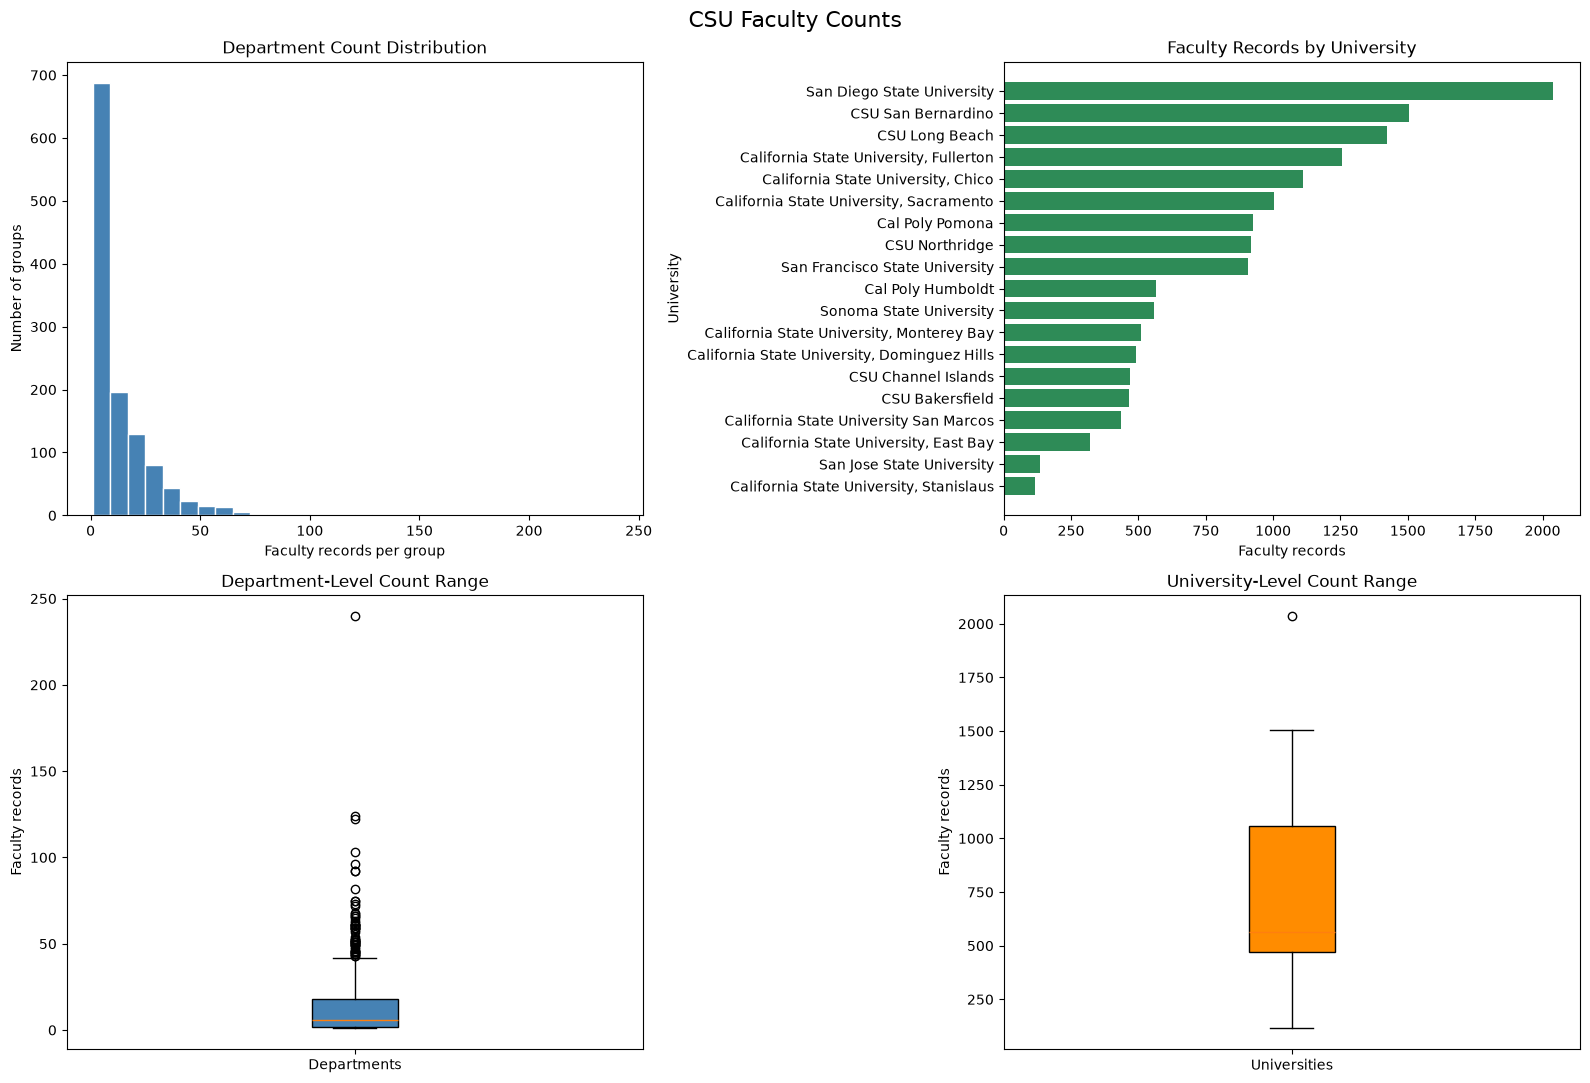

In [183]:
import matplotlib.pyplot as plt

faculty_summary.create_view("faculty_summary_grid")
csu_department_counts = [row[0] for row in faculty_summary.project("count").fetchall()]
csu_university_counts = conn.sql("SELECT university, SUM(count) AS faculty_count FROM faculty_summary_grid GROUP BY university ORDER BY faculty_count DESC").fetchall()
csu_universities = [row[0] for row in csu_university_counts]
csu_university_values = [row[1] for row in csu_university_counts]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes[0, 0].hist(csu_department_counts, bins=min(30, max(1, len(set(csu_department_counts)))), color="steelblue", edgecolor="white")
axes[0, 0].set(title="Department Count Distribution", xlabel="Faculty records per group", ylabel="Number of groups")
axes[0, 1].barh(csu_universities, csu_university_values, color="seagreen")
axes[0, 1].set(title="Faculty Records by University", xlabel="Faculty records", ylabel="University")
axes[0, 1].invert_yaxis()
axes[1, 0].boxplot(csu_department_counts, tick_labels=["Departments"], patch_artist=True, boxprops={"facecolor": "steelblue"})
axes[1, 0].set(title="Department-Level Count Range", ylabel="Faculty records")
axes[1, 1].boxplot(csu_university_values, tick_labels=["Universities"], patch_artist=True, boxprops={"facecolor": "darkorange"})
axes[1, 1].set(title="University-Level Count Range", ylabel="Faculty records")
fig.suptitle("CSU Faculty Counts", fontsize=16)
plt.tight_layout()
plt.show()


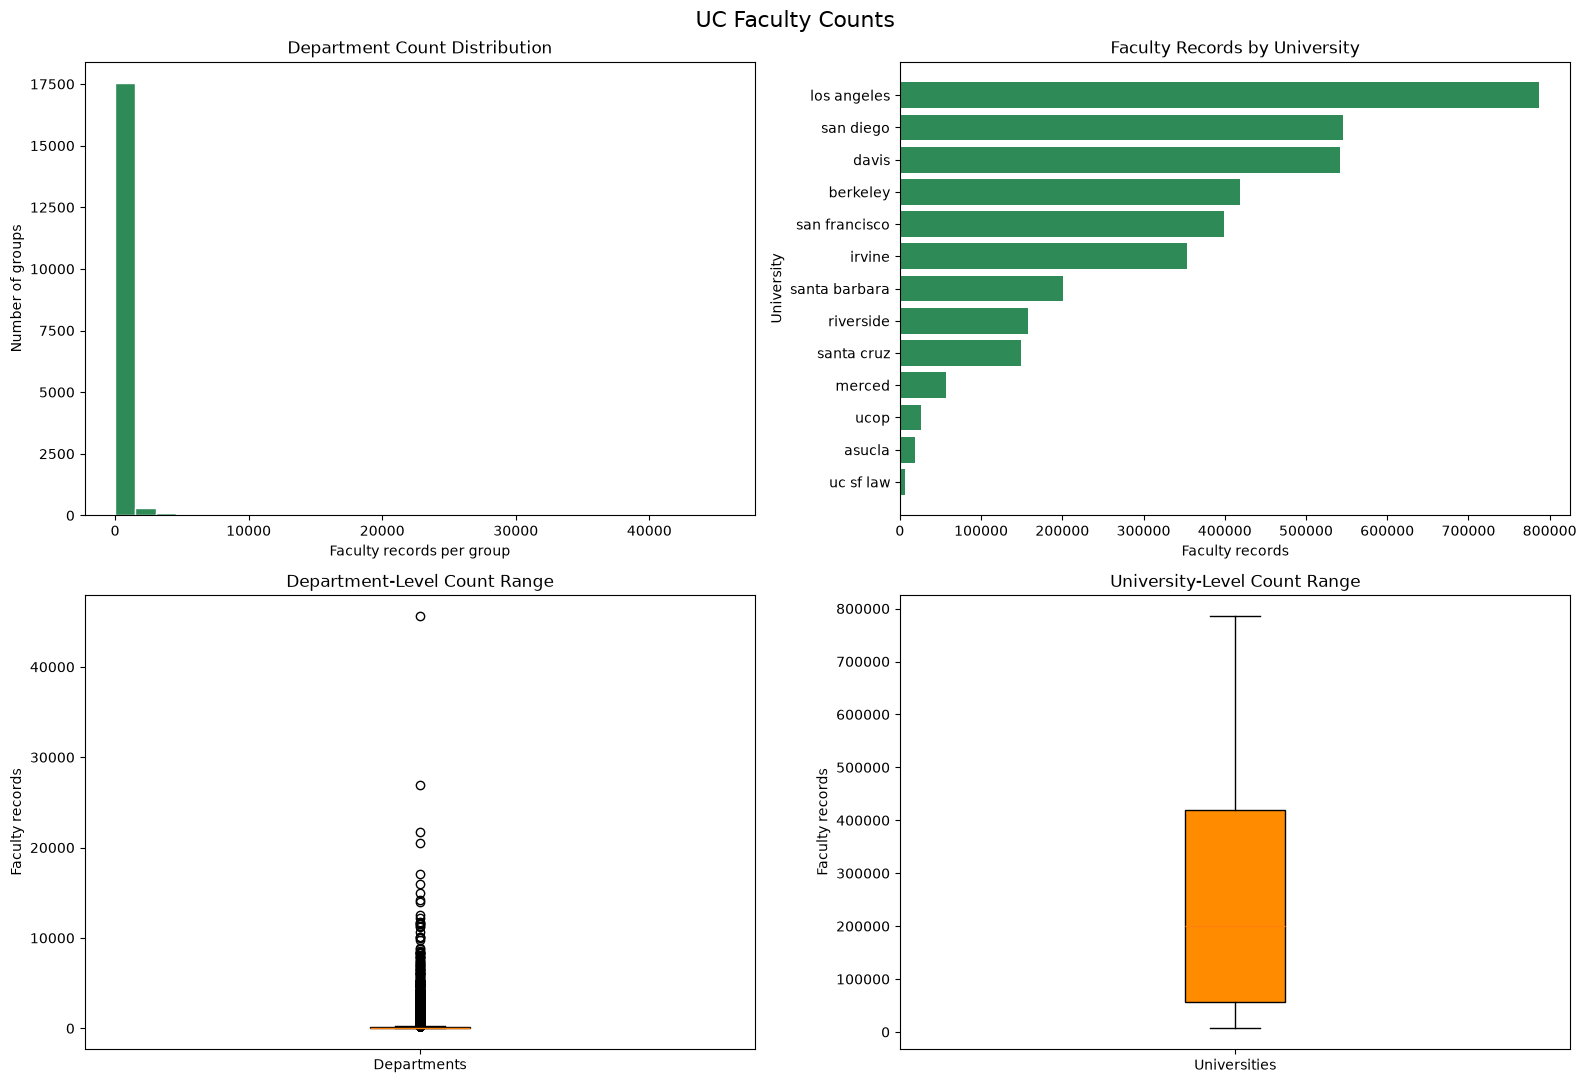

In [184]:
import matplotlib.pyplot as plt

uc_faculty_summary.create_view("uc_faculty_summary_grid")
uc_department_counts = [row[0] for row in uc_faculty_summary.project("count").fetchall()]
uc_university_counts = conn.sql("SELECT university, SUM(count) AS faculty_count FROM uc_faculty_summary_grid GROUP BY university ORDER BY faculty_count DESC").fetchall()
uc_universities = [row[0] for row in uc_university_counts]
uc_university_values = [row[1] for row in uc_university_counts]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes[0, 0].hist(uc_department_counts, bins=min(30, max(1, len(set(uc_department_counts)))), color="seagreen", edgecolor="white")
axes[0, 0].set(title="Department Count Distribution", xlabel="Faculty records per group", ylabel="Number of groups")
axes[0, 1].barh(uc_universities, uc_university_values, color="seagreen")
axes[0, 1].set(title="Faculty Records by University", xlabel="Faculty records", ylabel="University")
axes[0, 1].invert_yaxis()
axes[1, 0].boxplot(uc_department_counts, tick_labels=["Departments"], patch_artist=True, boxprops={"facecolor": "seagreen"})
axes[1, 0].set(title="Department-Level Count Range", ylabel="Faculty records")
axes[1, 1].boxplot(uc_university_values, tick_labels=["Universities"], patch_artist=True, boxprops={"facecolor": "darkorange"})
axes[1, 1].set(title="University-Level Count Range", ylabel="Faculty records")
fig.suptitle("UC Faculty Counts", fontsize=16)
plt.tight_layout()
plt.show()


## Specific Departments

In [185]:
computer_science_subset = conn.sql("""
    SELECT *
    FROM faculty_summary
    WHERE LOWER(department) LIKE '%computer science%'
    ORDER BY university, department
""")

computer_science_subset

┌─────────┬──────────────────────────────────────────────┬────────────────────────────────────────────────────────────┬───────┬───────────┬───────────┬──────────┬───────────┐
│ system  │                  university                  │                         department                         │ count │   mean    │  median   │   std    │    iqr    │
│ varchar │                   varchar                    │                          varchar                           │ int64 │  double   │  double   │  double  │  double   │
├─────────┼──────────────────────────────────────────────┼────────────────────────────────────────────────────────────┼───────┼───────────┼───────────┼──────────┼───────────┤
│ CSU     │ CSU Bakersfield                              │ Computer Sciences                                          │    15 │  64025.15 │  73124.99 │ 64779.48 │ 119068.78 │
│ CSU     │ CSU Bakersfield                              │ Computer and Electric Engineering and Computer Science     │     5

In [201]:

cs_ci_subset = conn.sql("""
    SELECT *
    FROM joined_faculty
    WHERE school = 'CSU Channel Islands' AND department_scraped LIKE '%Computer Science%'
""")

cs_ci_subset

┌─────────────────────────┬───────────────────────────────────────────────────────┬──────────────────────────┬───────────┬──────────┬──────────┬────────────┬────────────┬────────────┬────────────┬────────┬───────────┬───────────────┬──────────────────┬────────┬────────────────────┬─────────────────────────────┬────────┬────────────────────────┬────────────────────────────────┬─────────────────────┬──────────────┬─────────┬────────────┬────────────┐
│          name           │                          job                          │ department_transparentCA │   base    │ overtime │  other   │ benefitsee │ benefitser │ benefitsdc │ benefitshw │  ual   │ totalpay  │ totalbenefits │ totalpaybenefits │ notes  │ year_transparentCA │           agency            │ status │         title          │       department_scraped       │       school        │ year_scraped │  major  │ source_url │ start_date │
│         varchar         │                        varchar                        │          d

In [202]:
cs_ci_subset = conn.sql("""
    SELECT DISTINCT name
    FROM joined_faculty
    WHERE school = 'CSU Channel Islands'
      AND department_scraped ILIKE '%Computer Science%'
    ORDER BY name
""")

cs_ci_subset

┌─────────────────────────┐
│          name           │
│         varchar         │
├─────────────────────────┤
│ Brian P Thoms           │
│ Christopher Peter Onzol │
│ Eric Elwood Gentry      │
│ Jason T Isaacs          │
│ John Patrick Dempsey    │
│ Kevin Teruo Scrivnor    │
│ Kira Minkova            │
│ Kurt P. Zierhut         │
│ Puneet Sharma           │
│ Ramon Flores            │
│ Richard Alex Wasniowski │
│ Richard I Zins          │
│ Sami Muhsin Al-Salman   │
│ Scarlet Relle           │
│ Scott Feister           │
└─────────────────────────┘
          15 rows        

In [206]:
cs_ci_faculty_comparison = conn.sql("""
    WITH expected_faculty(first_name, last_name) AS (
        VALUES
            ('Bahareh', 'Abbasi'), ('Reza', 'Abdolee'), ('Vedang', 'Chauhan'),
            ('Jason', 'Isaacs'), ('Scott', 'Feister'), ('Michael', 'Soltys'),
            ('Brian', 'Thoms'), ('Vida', 'Vakilian'), ('Sami', 'Al-Salman'),
            ('Marc', 'Aten'), ('Eric', 'Gentry'), ('Kira', 'Minkova'),
            ('John', 'Dempsey'), ('Christopher', 'Onzol'), ('Ronald', 'Rieger'),
            ('Kevin', 'Scrivnor'), ('Andrea', 'Skinner'), ('Puneet', 'Sharma'),
            ('Richard', 'Wasniowski'), ('Kurt', 'Zierhut'), ('Richard', 'Zins')
    ),
    joined_names AS (
        SELECT DISTINCT
            name,
            LOWER(SPLIT_PART(TRIM(name), ' ', 1)) AS first_name,
            LOWER(REGEXP_EXTRACT(TRIM(name), '([^ ]+)$', 1)) AS last_name
        FROM joined_faculty
        WHERE school = 'CSU Channel Islands'
          AND department_scraped ILIKE '%Computer Science%'
    ),
    expected_results AS (
        SELECT
            CONCAT(e.first_name, ' ', e.last_name) AS name,
            CASE
                WHEN EXISTS (
                    SELECT 1
                    FROM joined_names j
                    WHERE j.first_name = LOWER(e.first_name)
                      AND (
                          e.first_name <> 'Richard'
                          OR j.last_name = LOWER(e.last_name)
                      )
                ) THEN 'In both list and table'
                ELSE 'In list, not in table'
            END AS list_table_status
        FROM expected_faculty e
    ),
    table_only_results AS (
        SELECT
            j.name,
            'In table, not in list' AS list_table_status
        FROM joined_names j
        WHERE NOT EXISTS (
            SELECT 1
            FROM expected_faculty e
            WHERE j.first_name = LOWER(e.first_name)
              AND (
                  e.first_name <> 'Richard'
                  OR j.last_name = LOWER(e.last_name)
              )
        )
    )
    SELECT * FROM expected_results
    UNION ALL
    SELECT * FROM table_only_results
    ORDER BY list_table_status, name
""")

cs_ci_faculty_comparison

┌────────────────────┬────────────────────────┐
│        name        │   list_table_status    │
│      varchar       │        varchar         │
├────────────────────┼────────────────────────┤
│ Brian Thoms        │ In both list and table │
│ Christopher Onzol  │ In both list and table │
│ Eric Gentry        │ In both list and table │
│ Jason Isaacs       │ In both list and table │
│ John Dempsey       │ In both list and table │
│ Kevin Scrivnor     │ In both list and table │
│ Kira Minkova       │ In both list and table │
│ Kurt Zierhut       │ In both list and table │
│ Puneet Sharma      │ In both list and table │
│ Richard Wasniowski │ In both list and table │
│ Richard Zins       │ In both list and table │
│ Sami Al-Salman     │ In both list and table │
│ Scott Feister      │ In both list and table │
│ Andrea Skinner     │ In list, not in table  │
│ Bahareh Abbasi     │ In list, not in table  │
│ Marc Aten          │ In list, not in table  │
│ Michael Soltys     │ In list, not in t

In [189]:
duplicate_name_report = conn.sql("""
    WITH name_counts AS (
        SELECT
            school AS university,
            name,
            COUNT(*) AS record_count
        FROM joined_faculty
        WHERE school IS NOT NULL
          AND name IS NOT NULL
        GROUP BY school, name
    )
    SELECT
        university,
        CASE
            WHEN record_count = 2 THEN 'Double-counted'
            WHEN record_count = 3 THEN 'Triple-counted'
            ELSE '4+ counted'
        END AS duplicate_category,
        COUNT(*) AS unique_faculty_names,
        SUM(record_count) AS joined_records
    FROM name_counts
    WHERE record_count >= 2
    GROUP BY university, duplicate_category
    ORDER BY university,
             CASE duplicate_category
                 WHEN 'Double-counted' THEN 1
                 WHEN 'Triple-counted' THEN 2
                 ELSE 3
             END
""")

duplicate_name_report

┌────────────────────────────────┬────────────────────┬──────────────────────┬────────────────┐
│           university           │ duplicate_category │ unique_faculty_names │ joined_records │
│            varchar             │      varchar       │        int64         │     int128     │
├────────────────────────────────┼────────────────────┼──────────────────────┼────────────────┤
│ CSU Bakersfield                │ Double-counted     │                   86 │            172 │
│ CSU Bakersfield                │ Triple-counted     │                   34 │            102 │
│ CSU Bakersfield                │ 4+ counted         │                   18 │             86 │
│ CSU Channel Islands            │ Double-counted     │                   93 │            186 │
│ CSU Channel Islands            │ Triple-counted     │                   43 │            129 │
│ CSU Channel Islands            │ 4+ counted         │                   27 │            124 │
│ CSU Long Beach                 │ Doubl

In [197]:
zero_salary_report = conn.sql("""
    SELECT
        school AS university,
        SUM(CASE WHEN base = 0 THEN 1 ELSE 0 END) AS zero_base_salary_records,
        COUNT(DISTINCT CASE WHEN base = 0 THEN name END) AS unique_names_with_zero_base_salary,
        COUNT(*) AS total_records,
        ROUND(
            100.0 * SUM(CASE WHEN base = 0 THEN 1 ELSE 0 END) / COUNT(*),
            2
        ) AS zero_base_salary_percent
    FROM joined_faculty
    WHERE school IS NOT NULL
    GROUP BY school
    ORDER BY zero_base_salary_records DESC, university
""")

zero_salary_report
zero_salary_report

┌──────────────────────────────────────────────┬──────────────────────────┬────────────────────────────────────┬───────────────┬──────────────────────────┐
│                  university                  │ zero_base_salary_records │ unique_names_with_zero_base_salary │ total_records │ zero_base_salary_percent │
│                   varchar                    │          int128          │               int64                │     int64     │          double          │
├──────────────────────────────────────────────┼──────────────────────────┼────────────────────────────────────┼───────────────┼──────────────────────────┤
│ San Diego State University                   │                      904 │                                607 │          2083 │                     43.4 │
│ CSU San Bernardino                           │                      621 │                                382 │          1506 │                    41.24 │
│ CSU Long Beach                               │                

In [194]:
header = conn.sql("""
    SELECT * 
    FROM joined_faculty
    LIMIT 1
""")

header

┌─────────────────┬──────────────────────────────────┬──────────────────────────┬───────────┬──────────┬────────┬────────────┬────────────┬────────────┬────────────┬────────┬───────────┬───────────────┬──────────────────┬────────┬────────────────────┬─────────────────────────────┬────────┬───────────┬─────────────────────┬───────────────────┬──────────────┬─────────┬────────────┬────────────┐
│      name       │               job                │ department_transparentCA │   base    │ overtime │ other  │ benefitsee │ benefitser │ benefitsdc │ benefitshw │  ual   │ totalpay  │ totalbenefits │ totalpaybenefits │ notes  │ year_transparentCA │           agency            │ status │   title   │ department_scraped  │      school       │ year_scraped │  major  │ source_url │ start_date │
│     varchar     │             varchar              │          double          │  double   │  double  │ double │   double   │   double   │   double   │   double   │ double │  double   │    double     │      

In [198]:
zero_base_with_paid_name_match = conn.sql("""
    SELECT
        zero_pay.school AS university,
        zero_pay.name,
        zero_pay.job AS zero_base_job,
        zero_pay.department_scraped AS zero_base_department,
        zero_pay.base AS zero_base_pay,
        zero_pay.totalpay AS zero_total_pay,
        paid.base AS matching_nonzero_base_pay,
        paid.totalpay AS matching_nonzero_total_pay,
        paid.job AS matching_nonzero_base_job,
        paid.department_scraped AS matching_nonzero_base_department
    FROM joined_faculty AS zero_pay
    INNER JOIN joined_faculty AS paid
        ON zero_pay.school = paid.school
       AND LOWER(TRIM(zero_pay.name)) = LOWER(TRIM(paid.name))
    WHERE zero_pay.base = 0
      AND paid.base > 0
    ORDER BY university, name, matching_nonzero_base_pay DESC
""")

zero_base_with_paid_name_match

┌─────────────────────────┬──────────────────────────┬───────────────────────────────────────────────────────┬────────────────────────────────┬───────────────┬────────────────┬───────────────────────────┬────────────────────────────┬───────────────────────────────────────┬──────────────────────────────────┐
│       university        │           name           │                     zero_base_job                     │      zero_base_department      │ zero_base_pay │ zero_total_pay │ matching_nonzero_base_pay │ matching_nonzero_total_pay │       matching_nonzero_base_job       │ matching_nonzero_base_department │
│         varchar         │         varchar          │                        varchar                        │            varchar             │    double     │     double     │          double           │           double           │                varchar                │             varchar              │
├─────────────────────────┼──────────────────────────┼───────────────────

In [199]:

fresno = conn.sql("""
    SELECT *
    FROM joined_faculty
    WHERE school LIKE '%Fresno%'
""")

fresno

┌─────────┬─────────┬──────────────────────────┬────────┬──────────┬────────┬────────────┬────────────┬────────────┬────────────┬────────┬──────────┬───────────────┬──────────────────┬────────┬────────────────────┬─────────┬────────┬─────────┬────────────────────┬─────────┬──────────────┬─────────┬────────────┬────────────┐
│  name   │   job   │ department_transparentCA │  base  │ overtime │ other  │ benefitsee │ benefitser │ benefitsdc │ benefitshw │  ual   │ totalpay │ totalbenefits │ totalpaybenefits │ notes  │ year_transparentCA │ agency  │ status │  title  │ department_scraped │ school  │ year_scraped │  major  │ source_url │ start_date │
│ varchar │ varchar │          double          │ double │  double  │ double │   double   │   double   │   double   │   double   │ double │  double  │    double     │      double      │ double │       int64        │ varchar │ double │ varchar │      varchar       │ varchar │   varchar    │ varchar │  varchar   │  varchar   │
└─────────┴─────────┴─